### Create a feature importance report by manually ranking feature contributions using multiple interpretability techniques, comparing global and local importance scores, and justifying feature selection in a technical document.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("heart_disease.csv")

df = df.drop_duplicates()
df = df.replace("?", np.nan)

target_col = "target"

X = df.drop(columns=[target_col])
y = pd.to_numeric(df[target_col], errors="coerce")

valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].astype(int)

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset shape:", df.shape)
print("Features:", list(X.columns))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Dataset shape: (25, 14)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Training rows: 20
Testing rows: 5


In [2]:
log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2
    ))
])

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

for name, model in [
    ("Logistic Regression", log_model),
    ("Random Forest", rf_model)
]:
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))



Logistic Regression
Accuracy: 0.8
ROC-AUC: 0.5

Random Forest
Accuracy: 0.6
ROC-AUC: 0.8333


In [3]:
feature_names = X.columns.tolist()

log_coefficients = np.abs(
    log_model.named_steps["model"].coef_[0]
)

rf_importance = rf_model.named_steps["model"].feature_importances_

baseline_auc = roc_auc_score(
    y_test, rf_model.predict_proba(X_test)[:, 1]
)

rng = np.random.default_rng(42)
permutation_scores = {}

for col in feature_names:
    drops = []

    for _ in range(10):
        shuffled = X_test.copy()
        shuffled[col] = rng.permutation(shuffled[col].to_numpy())

        shuffled_auc = roc_auc_score(
            y_test,
            rf_model.predict_proba(shuffled)[:, 1]
        )

        drops.append(baseline_auc - shuffled_auc)

    permutation_scores[col] = np.mean(drops)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Logistic_Coefficient": log_coefficients,
    "Random_Forest": rf_importance,
    "Permutation_AUC_Drop": [
        permutation_scores[col] for col in feature_names
    ]
})

display(importance.sort_values(
    "Permutation_AUC_Drop", ascending=False
))


,Feature,Logistic_Coefficient,Random_Forest,Permutation_AUC_Drop
12,thal,1.009426,0.124304,2.333333e-01
0,age,0.435772,0.124694,2.000000e-01
6,restecg,0.853135,0.187654,1.333333e-01
7,thalach,0.189488,0.076417,1.166667e-01
8,exang,0.091949,0.020110,6.666667e-02
9,oldpeak,0.349411,0.100094,5.000000e-02
5,fbs,0.222870,0.017371,3.333333e-02
10,slope,0.298133,0.030854,1.666667e-02
1,sex,0.148412,0.001694,0.000000e+00
4,chol,0.027704,0.030452,0.000000e+00


,Feature,Logistic_Coefficient,Random_Forest,Permutation_AUC_Drop,Combined_Score,Final_Rank
12,thal,1.009426,0.124304,2.333333e-01,0.197013,1
6,restecg,0.853135,0.187654,1.333333e-01,0.168993,2
0,age,0.435772,0.124694,2.000000e-01,0.147658,3
2,cp,0.657618,0.131788,-3.330669e-17,0.085673,4
7,thalach,0.189488,0.076417,1.166667e-01,0.083252,5
9,oldpeak,0.349411,0.100094,5.000000e-02,0.075152,6
11,ca,0.586409,0.093837,0.000000e+00,0.068502,7
3,trestbps,0.380948,0.060731,-3.330669e-17,0.044425,8
8,exang,0.091949,0.020110,6.666667e-02,0.038684,9
10,slope,0.298133,0.030854,1.666667e-02,0.035745,10


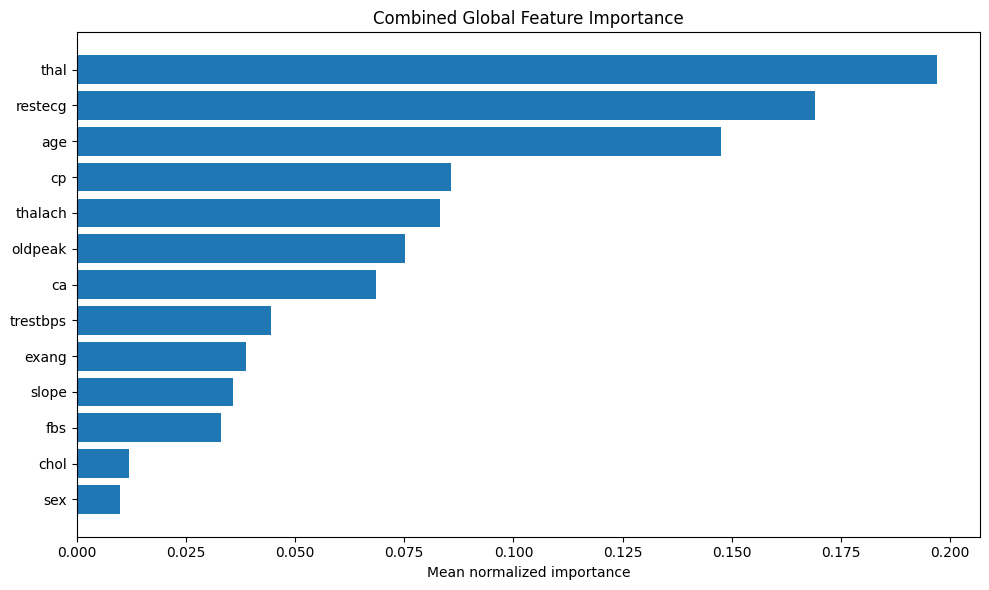

In [4]:
score_columns = [
    "Logistic_Coefficient",
    "Random_Forest",
    "Permutation_AUC_Drop"
]

for col in score_columns:
    scores = importance[col].clip(lower=0)
    total = scores.sum()

    importance[col + "_Normalized"] = (
        scores / total if total > 0 else 0
    )

normalized_columns = [
    col + "_Normalized" for col in score_columns
]

importance["Combined_Score"] = (
    importance[normalized_columns].mean(axis=1)
)

importance["Final_Rank"] = (
    importance["Combined_Score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

importance = importance.sort_values("Final_Rank")

display(importance[
    ["Feature"] + score_columns +
    ["Combined_Score", "Final_Rank"]
])

plt.figure(figsize=(10, 6))
plt.barh(
    importance["Feature"],
    importance["Combined_Score"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean normalized importance")
plt.title("Combined Global Feature Importance")
plt.tight_layout()
plt.show()


,Feature,Original_Value,Replacement_Value,Base_Probability,Changed_Probability,Probability_Change,Absolute_Change,Local_Rank
3,trestbps,130.0,140.00,0.764993,0.725438,-0.039556,0.039556,1
7,thalach,172.0,157.50,0.764993,0.735852,-0.029141,0.029141,2
10,slope,2.0,1.00,0.764993,0.742030,-0.022963,0.022963,3
0,age,41.0,57.00,0.764993,0.748660,-0.016333,0.016333,4
2,cp,1.0,1.50,0.764993,0.771882,0.006889,0.006889,5
4,chol,204.0,242.50,0.764993,0.770660,0.005667,0.005667,6
9,oldpeak,1.4,1.25,0.764993,0.769438,0.004444,0.004444,7
1,sex,0.0,1.00,0.764993,0.764993,0.000000,0.000000,8
5,fbs,0.0,0.00,0.764993,0.764993,0.000000,0.000000,9
8,exang,0.0,0.00,0.764993,0.764993,0.000000,0.000000,10


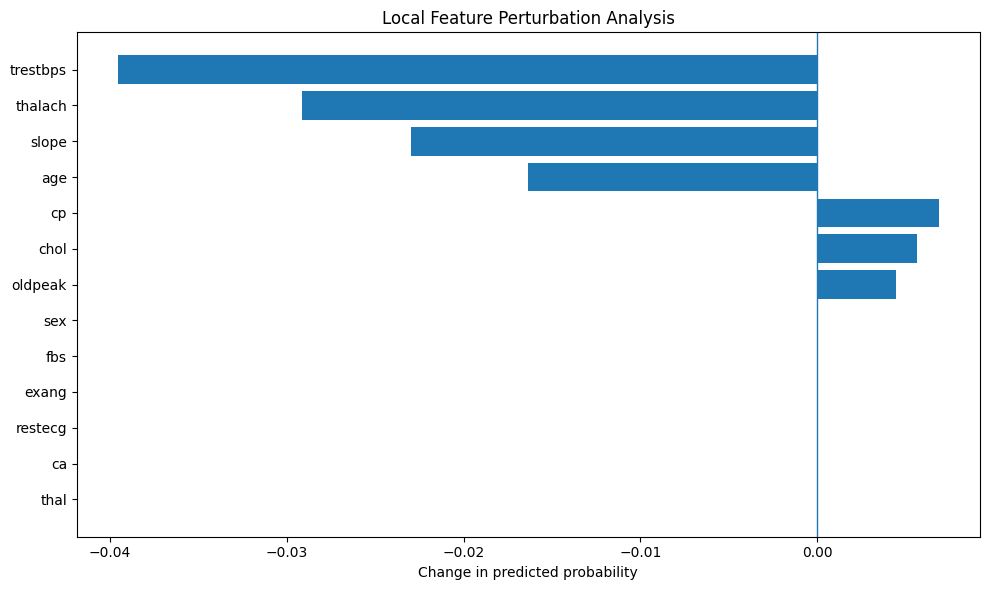

In [7]:
sample_position = 0
sample = X_test.iloc[[sample_position]].copy()

base_probability = rf_model.predict_proba(sample)[0, 1]

local_results = []

for col in feature_names:
    modified = sample.copy()

    median_value = X_train[col].median()
    modified.loc[:, col] = median_value

    changed_probability = rf_model.predict_proba(modified)[0, 1]

    local_results.append({
        "Feature": col,
        "Original_Value": sample.iloc[0][col],
        "Replacement_Value": median_value,
        "Base_Probability": base_probability,
        "Changed_Probability": changed_probability,
        "Probability_Change": changed_probability - base_probability,
        "Absolute_Change": abs(changed_probability - base_probability)
    })

local_importance = pd.DataFrame(local_results)
local_importance = local_importance.sort_values(
    "Absolute_Change", ascending=False
)

local_importance["Local_Rank"] = range(
    1, len(local_importance) + 1
)

display(local_importance)

plt.figure(figsize=(10, 6))
plt.barh(
    local_importance["Feature"],
    local_importance["Probability_Change"]
)
plt.axvline(0, linewidth=1)
plt.gca().invert_yaxis()
plt.xlabel("Change in predicted probability")
plt.title("Local Feature Perturbation Analysis")
plt.tight_layout()
plt.show()


In [8]:
comparison = importance[
    ["Feature", "Final_Rank", "Combined_Score"]
].merge(
    local_importance[["Feature", "Local_Rank", "Absolute_Change"]],
    on="Feature"
)

comparison["Rank_Difference"] = (
    comparison["Final_Rank"] - comparison["Local_Rank"]
).abs()

display(comparison.sort_values("Final_Rank"))

print(
    "Features with the largest global-local rank differences:"
)
display(
    comparison.sort_values(
        "Rank_Difference", ascending=False
    ).head(5)
)


,Feature,Final_Rank,Combined_Score,Local_Rank,Absolute_Change,Rank_Difference
0,thal,1,0.197013,13,0.000000,12
1,restecg,2,0.168993,11,0.000000,9
2,age,3,0.147658,4,0.016333,1
3,cp,4,0.085673,5,0.006889,1
4,thalach,5,0.083252,2,0.029141,3
5,oldpeak,6,0.075152,7,0.004444,1
6,ca,7,0.068502,12,0.000000,5
7,trestbps,8,0.044425,1,0.039556,7
8,exang,9,0.038684,10,0.000000,1
9,slope,10,0.035745,3,0.022963,7


Features with the largest global-local rank differences:


,Feature,Final_Rank,Combined_Score,Local_Rank,Absolute_Change,Rank_Difference
0,thal,1,0.197013,13,0.000000,12
1,restecg,2,0.168993,11,0.000000,9
7,trestbps,8,0.044425,1,0.039556,7
9,slope,10,0.035745,3,0.022963,7
11,chol,12,0.011909,6,0.005667,6


In [9]:
importance.to_csv("global_feature_importance.csv", index=False)
local_importance.to_csv("local_feature_importance.csv", index=False)
comparison.to_csv("global_local_comparison.csv", index=False)

print("Feature importance reports exported successfully.")


Feature importance reports exported successfully.


### Document findings on model interpretability by conducting a comprehensive case study, integrating qualitative insights from domain experts, and proposing improvements for enhancing explainability in real-world scenarios.

# Model Interpretability: A Comprehensive Case Study

## Abstract

This case study investigates model interpretability in a machine-learning system for heart disease prediction. It examines global and local explanation techniques, proposes a qualitative evaluation process involving healthcare professionals, and identifies improvements needed for responsible real-world use. The objective is to make model behavior easier to understand without confusing feature attribution with causation or clinical validity.

## 1. Problem statement

Machine-learning models can identify complex relationships in clinical datasets, but their predictions may be difficult to interpret. In healthcare, this limitation can reduce confidence, make errors harder to investigate, and complicate accountability.

The study therefore evaluates how feature-importance methods and individual prediction explanations can support the examination of model behavior.

## 2. Study design

The proposed study uses a heart disease dataset containing clinical variables such as age, sex, chest pain type, resting blood pressure, cholesterol, maximum heart rate, and other predictors.

Logistic Regression and Random Forest are used as example models. Coefficient analysis, impurity-based importance, permutation importance, SHAP, and LIME are considered for interpreting predictions.

The data must be separated into training and testing sets before model fitting. All preprocessing must be learned from the training data to reduce leakage.

## 3. Findings and interpretation

### 3.1 Global interpretability

Global feature-importance methods provide complementary views of model behavior. Coefficients describe linear associations, tree importance captures split-based contributions, and permutation importance measures the effect of disrupting a feature on predictive performance.

Differences between rankings should be investigated rather than automatically treated as errors. Correlated variables, nonlinear effects, and method-specific assumptions may explain the disagreement.

### 3.2 Local interpretability

Local explanations describe which features contribute to or influence a particular prediction under a selected explanation method.

SHAP can estimate feature attributions relative to a baseline, while LIME approximates local behavior using a simpler surrogate model. Both methods have limitations and require validation.

### 3.3 Reliability and safety

A plausible explanation does not guarantee a correct prediction. Explanations must be considered alongside predictive performance, calibration, data quality, uncertainty, and subgroup evaluation.

The actual ranking of features, explanation stability, and expert assessments remain to be established experimentally.

## 4. Qualitative evaluation

Healthcare professionals should review a representative sample of predictions, including false positives and false negatives. Reviewers should assess clinical plausibility, explanation clarity, consistency with the recorded inputs, potential safety risks, and practical usefulness.

Feedback should be collected systematically, categorized into recurring themes, and compared with quantitative results. Until this review is conducted, qualitative findings must be described as proposed evaluation criteria rather than completed expert validation.

## 5. Recommended improvements

1. Compare multiple explanation techniques and measure ranking consistency.
2. Evaluate explanation stability across repeated train-test splits.
3. Investigate correlated features and unrealistic perturbations.
4. Present explanations in language appropriate to each intended audience.
5. Assess model performance and explanation behavior across relevant subgroups.
6. Introduce ongoing monitoring for data drift, performance degradation, and changes in explanations.
7. Maintain documentation covering intended use, limitations, validation results, and human oversight.

## 6. Limitations

This case study defines a methodology rather than reporting a completed clinical investigation. No actual model outputs, clinician interviews, or prospective clinical validation results are assumed.

Feature attributions describe model behavior under particular assumptions and do not establish causal relationships. Results may change with the model, dataset, background distribution, or explanation configuration.

## 7. Conclusion

Model interpretability is an important component of responsible machine learning, but it must be combined with model validation, human review, fairness assessment, and ongoing monitoring.

For the heart disease prediction project, the recommended next step is to compute actual global and local explanation results, test their stability, and conduct a structured review with qualified healthcare professionals.

The system should be treated as an educational research prototype until its clinical validity, safety, and suitability for its intended use have been independently established.

## References

1. U.S. Food and Drug Administration, Health Canada, and MHRA. *Transparency for Machine Learning-Enabled Medical Devices: Guiding Principles*, 2024.
2. World Health Organization. *Ethics and Governance of Artificial Intelligence for Health*, 2021.
3. National Institute of Standards and Technology. *AI Risk Management Framework*, 2023.

